# Deep Learning aplicado a Vision Computacional
# Fase de Modelado 1
### Juan Pablo Arteaga Paiño | A01665795

## Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from PIL import Image

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
SOURCE_DIR = '/content/drive/MyDrive/DeepLearning_ProyectoBenji/dataset'

TRAIN_IMG_DIR = os.path.join(SOURCE_DIR, "split", 'train', 'images')
TRAIN_MASK_DIR = os.path.join(SOURCE_DIR, "split", 'train', 'masks')

VAL_IMG_DIR = os.path.join(SOURCE_DIR, "split", 'val', 'images')
VAL_MASK_DIR = os.path.join(SOURCE_DIR, "split", 'val', 'masks')

TEST_IMG_DIR = os.path.join(SOURCE_DIR, "split", 'test', 'images')
TEST_MASK_DIR = os.path.join(SOURCE_DIR, "split", 'test', 'masks')

SEED = 67

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: []


## Resolucion y dimensionalidad

In [ ]:
# Verificar la existencia de directorios antes de listar archivos
train_files = sorted([ f for f in os.listdir(TRAIN_IMG_DIR) if f.lower().endswith('.jpg') ]) if os.path.exists(TRAIN_IMG_DIR) else []
val_files = sorted([ f for f in os.listdir(VAL_IMG_DIR) if f.lower().endswith('.jpg') ]) if os.path.exists(VAL_IMG_DIR) else []
test_files = sorted([ f for f in os.listdir(TEST_IMG_DIR) if f.lower().endswith('.jpg') ]) if os.path.exists(TEST_IMG_DIR) else []

# Seleccionar una muestra (usando train_files como base asegurada)
sample_path = train_files[0]

# Obtener el nombre base sin la extensión
sample_name = os.path.splitext(sample_path)[0]
mask_path = os.path.join(TRAIN_MASK_DIR, f"{sample_name}.png")

# Cargar imagen y máscara
image = Image.open(os.path.join(TRAIN_IMG_DIR, sample_path)).convert("RGB")
mask = Image.open(mask_path)

mask_array = np.array(mask)

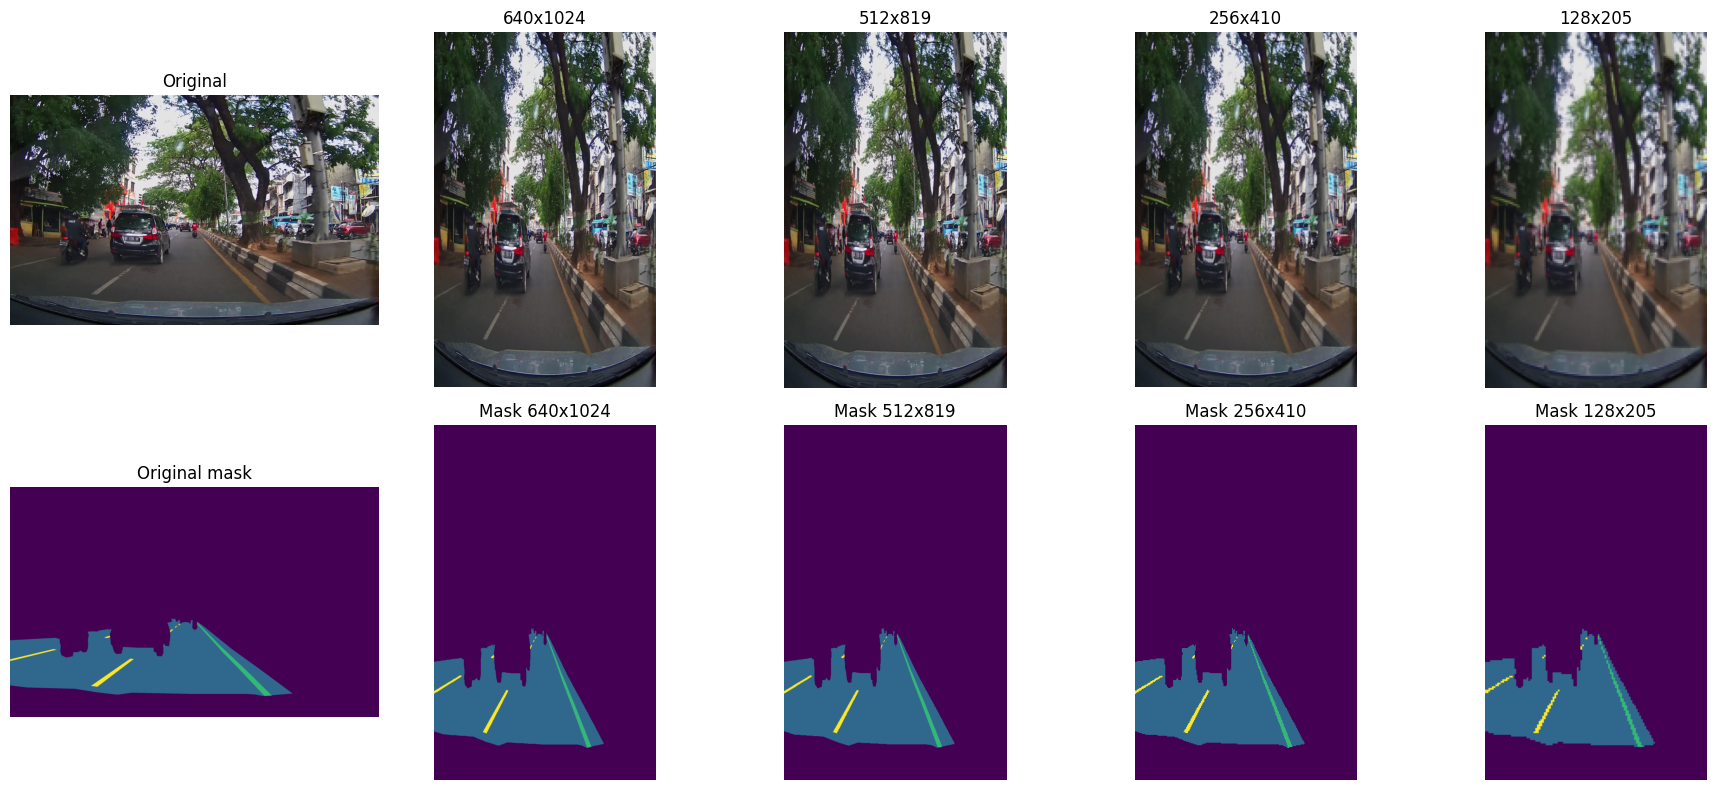

In [ ]:
RESOLUTIONS = [
    (640, 1024),
    (512, 819),
    (256, 410),
    (128, 205)
]

fig, axes = plt.subplots(
    2, len(RESOLUTIONS) + 1,
    figsize=(18, 8)
)

# Imagen original
axes[0, 0].imshow(image)
axes[0, 0].set_title("Original")

# Máscara original
axes[1, 0].imshow(mask_array, cmap="viridis", vmin=0, vmax=3)
axes[1, 0].set_title("Original mask")

for i, (width, height) in enumerate(RESOLUTIONS):

    resized_image = image.resize(
        (width, height),
        Image.Resampling.BILINEAR
    )

    resized_mask = mask.resize(
        (width, height),
        Image.Resampling.NEAREST
    )

    axes[0, i + 1].imshow(resized_image)
    axes[0, i + 1].set_title(f"{width}x{height}")

    axes[1, i + 1].imshow(
        np.array(resized_mask),
        cmap="viridis",
        vmin=0,
        vmax=3
    )

    axes[1, i + 1].set_title(f"Mask {width}x{height}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

###

## Encoder

In [ ]:
resolution = (512, 820)
inputs = keras.Input(shape=resolution[::-1] + (3,))

x = layers.Conv2D(16, 3, padding="same", activation="relu")(inputs)
x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)
block1 = x

x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
block2 = x

x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
block3 = x

x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
block4 = x

model = keras.Model(inputs=inputs, outputs=[block1, block2, block3, block4])
layers = model.layers
print(len(layers))

vgg_input = layers[0].output
vgg_layers = layers[1:]

model.summary()

12


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 820, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 820, 512, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 820, 512, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 410, 256, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 410, 256, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 410, 256, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 205, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 205, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 205, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 102, 64, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 102, 64, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 102, 64, 128)   │       147,584 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 293,520 (1.12 MB)

 Trainable params: 293,520 (1.12 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Build a model that returns the layer outputs
layer_outputs = [layer.output for layer in vgg_layers]
features = Model(inputs =  vgg_input, outputs = layer_outputs)

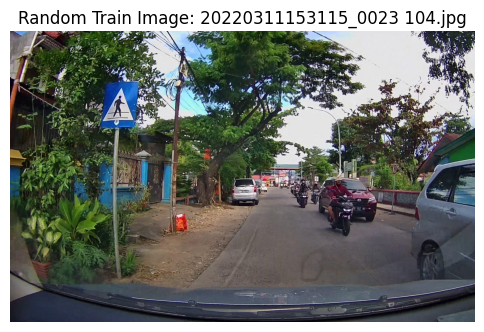

In [ ]:
# Seleccionar una imagen aleatoria del conjunto de entrenamiento
random_filename = random.choice(train_files)
random_image_path = os.path.join(TRAIN_IMG_DIR, random_filename)

# Cargar y mostrar la imagen original
random_img = Image.open(random_image_path).convert("RGB")
plt.figure(figsize=(6, 6))
plt.imshow(random_img)
plt.title(f"Random Train Image: {random_filename}")
plt.axis('off')
plt.show()

In [ ]:
def show_layer_outputs(random_img, layer):
  # Preprocesar la imagen elegida para que coincida con el input del modelo
  resized_input_img = random_img.resize(resolution, Image.Resampling.BILINEAR)

  img_tensor = np.array(resized_input_img) / 255.0  # Normalización básica
  img_tensor = np.expand_dims(img_tensor, axis=0)   # Agregar dimensión de lote

  # Extraer las características usando el modelo 'features'
  extracted_features = features.predict(img_tensor)

  # La primera capa convolucional corresponde al primer output (bloque 1)
  f1 = extracted_features[layer]
  print(f"Capa {layer+1}: ")
  print(f"Dimensiones del feature map de la capa {layer+1}: {f1.shape}")

  # Visualizar los primeros 3 canales del mapa de características
  plt.figure(figsize=(15, 5))
  for n in range(3):
      ax = plt.subplot(1, 3, n + 1)
      plt.imshow(f1[0, :, :, n], cmap='viridis')
      plt.title(f"Channel {n+1}")
      plt.axis('off')

  plt.subplots_adjust(wspace=0.1, hspace=0.1)
  plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 547ms/step
Capa 1: 
Dimensiones del feature map de la capa 1: (1, 820, 512, 16)


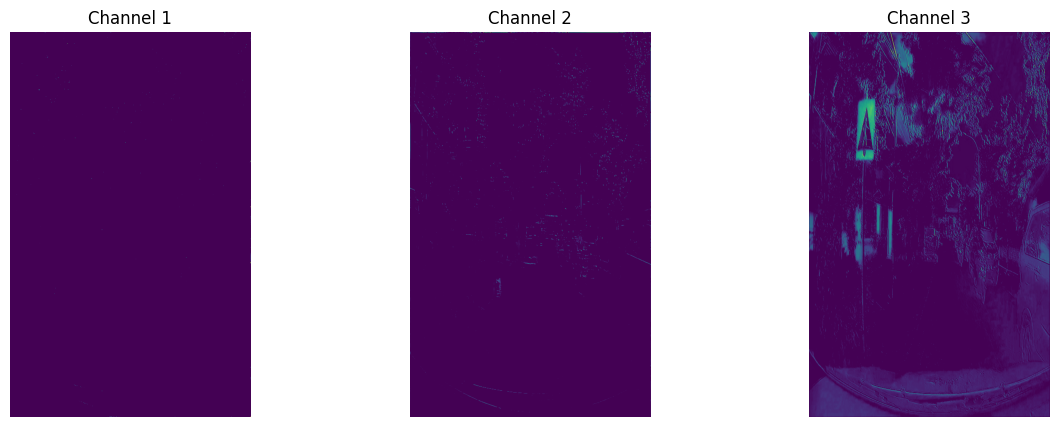

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step
Capa 2: 
Dimensiones del feature map de la capa 2: (1, 820, 512, 16)


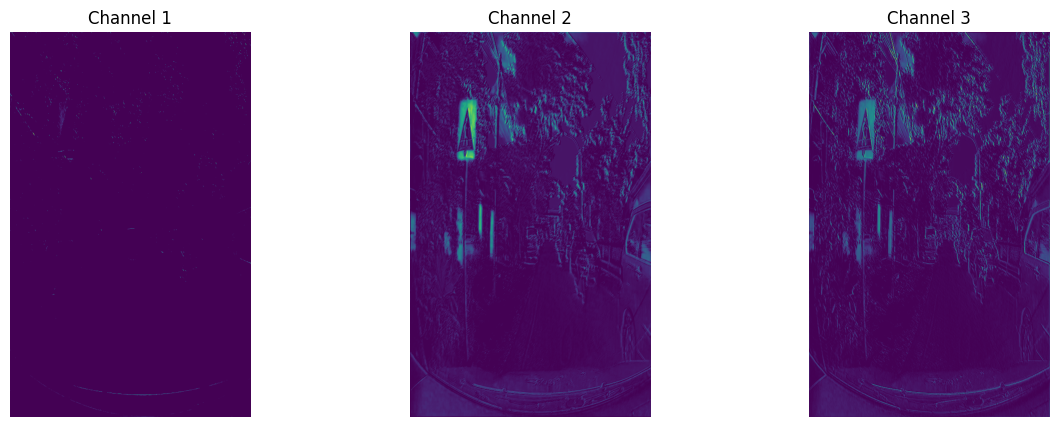

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 597ms/step
Capa 3: 
Dimensiones del feature map de la capa 3: (1, 410, 256, 16)


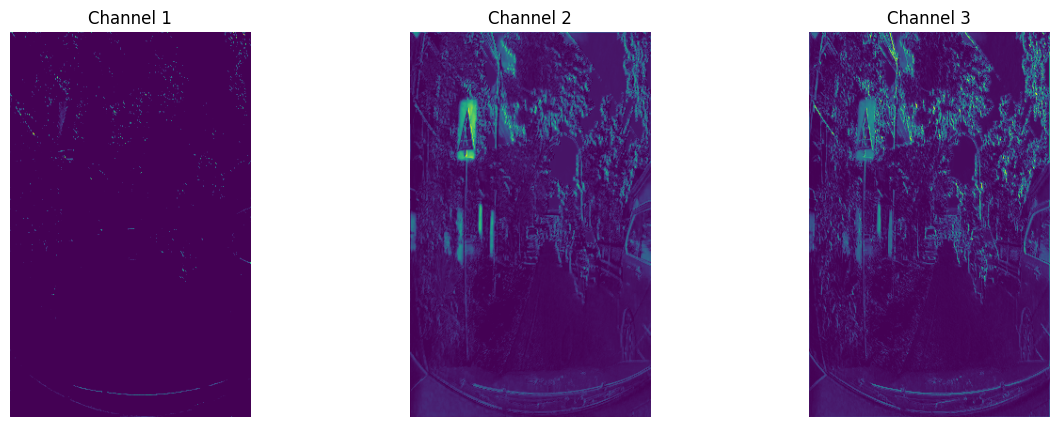

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 503ms/step
Capa 4: 
Dimensiones del feature map de la capa 4: (1, 410, 256, 32)


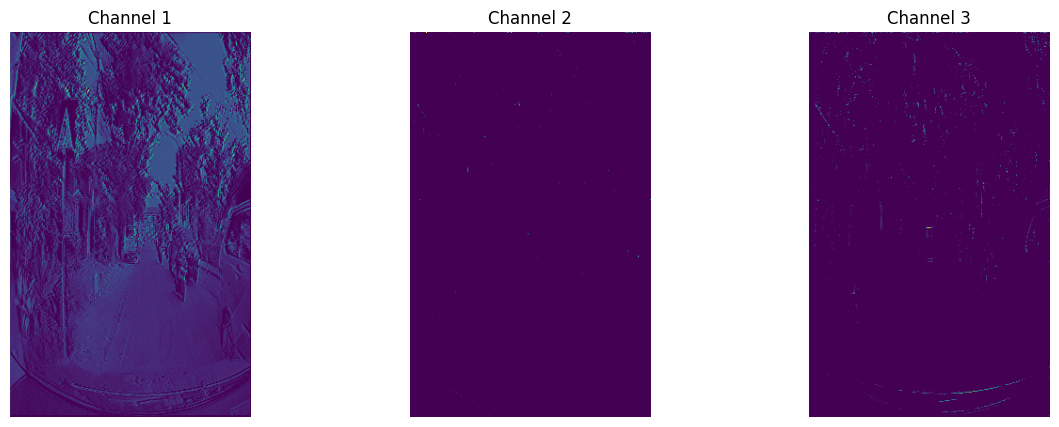

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step
Capa 5: 
Dimensiones del feature map de la capa 5: (1, 410, 256, 32)


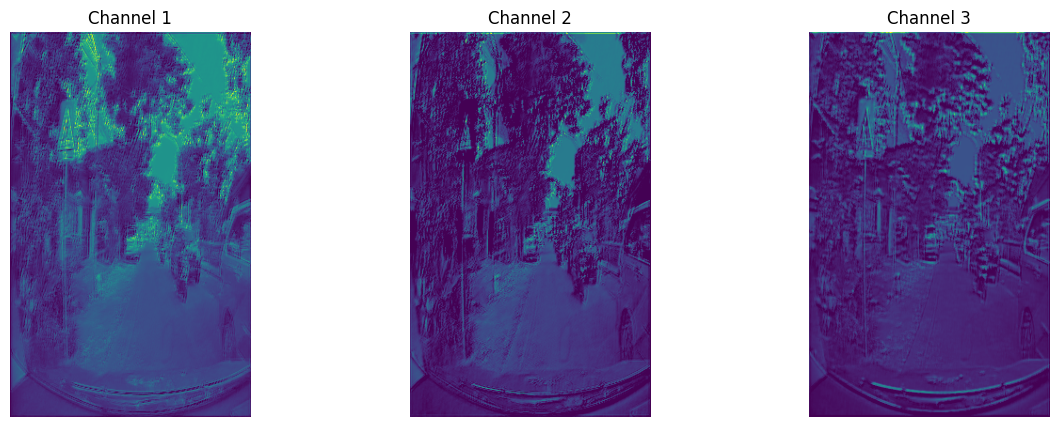

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step
Capa 6: 
Dimensiones del feature map de la capa 6: (1, 205, 128, 32)


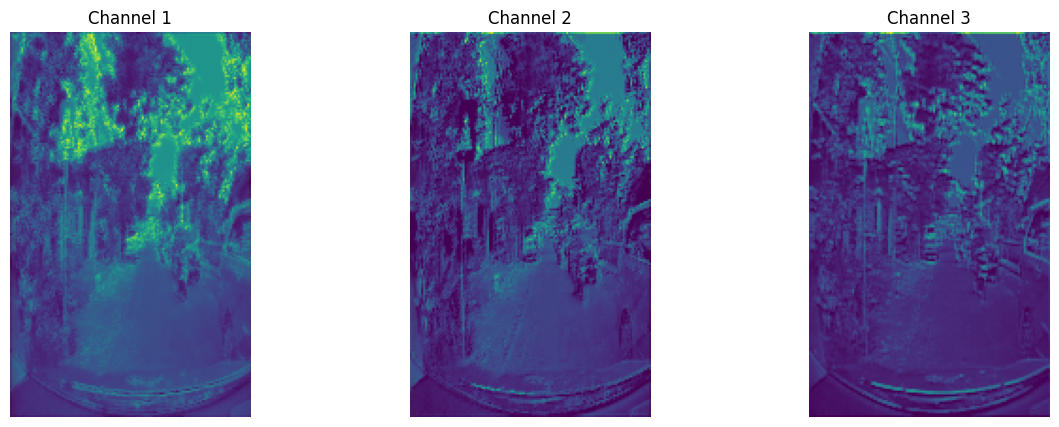

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
Capa 7: 
Dimensiones del feature map de la capa 7: (1, 205, 128, 64)


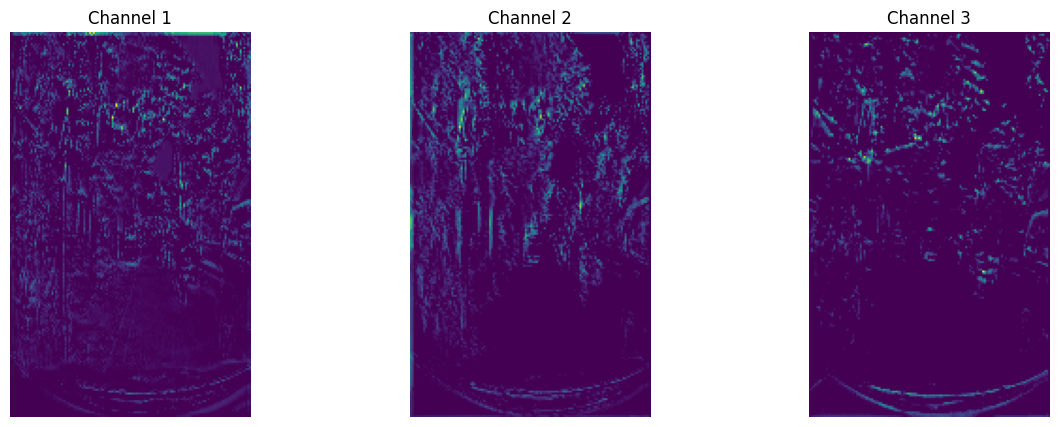

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step
Capa 8: 
Dimensiones del feature map de la capa 8: (1, 205, 128, 64)


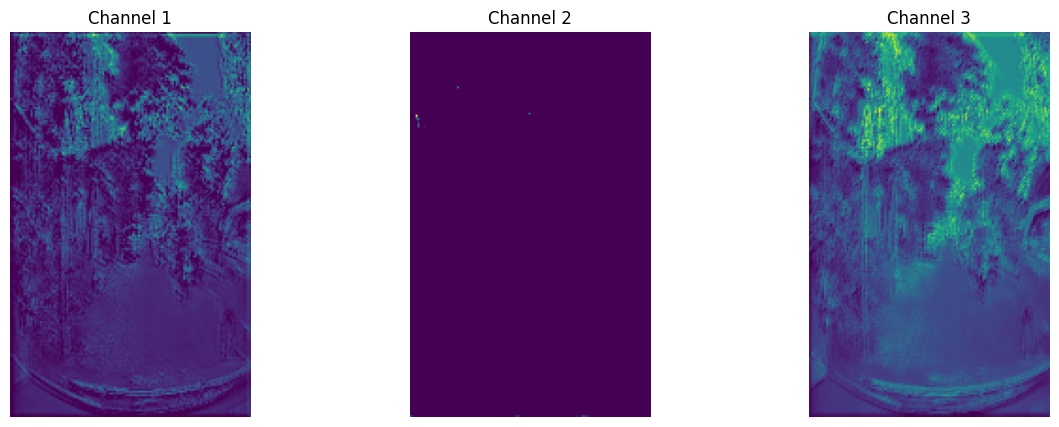

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step
Capa 9: 
Dimensiones del feature map de la capa 9: (1, 102, 64, 64)


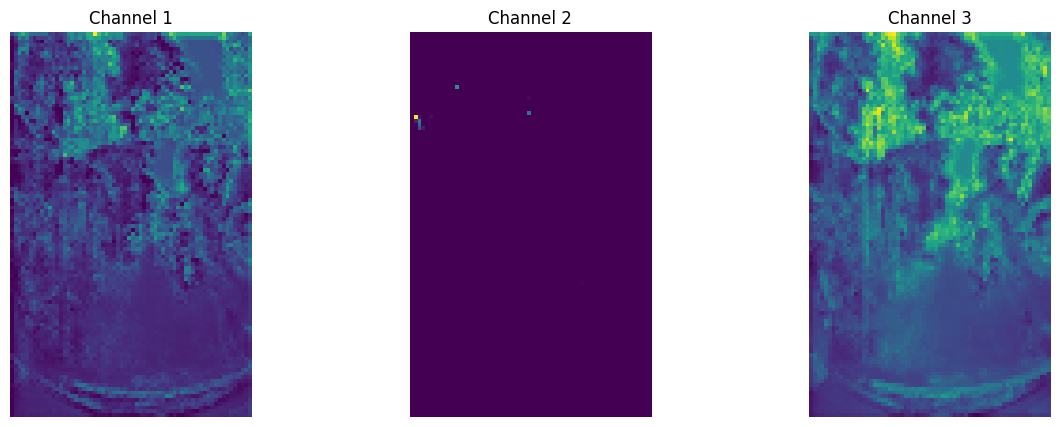

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step
Capa 10: 
Dimensiones del feature map de la capa 10: (1, 102, 64, 128)


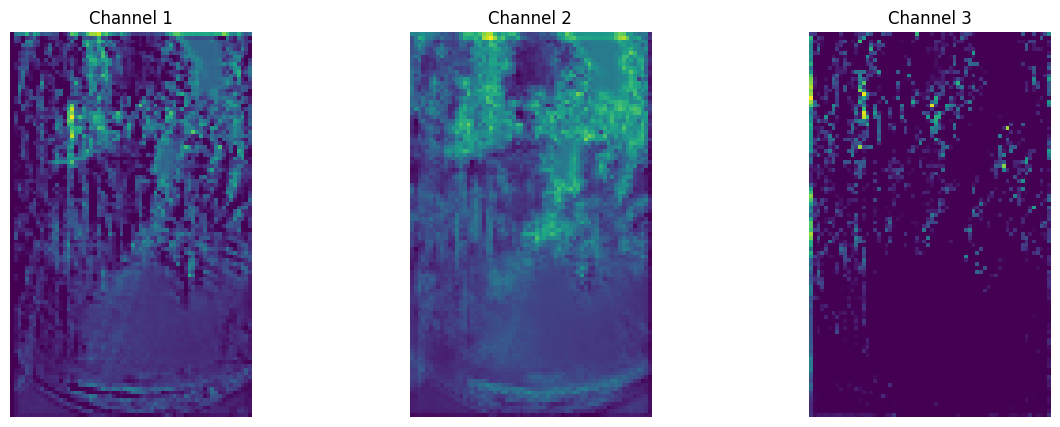

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step
Capa 11: 
Dimensiones del feature map de la capa 11: (1, 102, 64, 128)


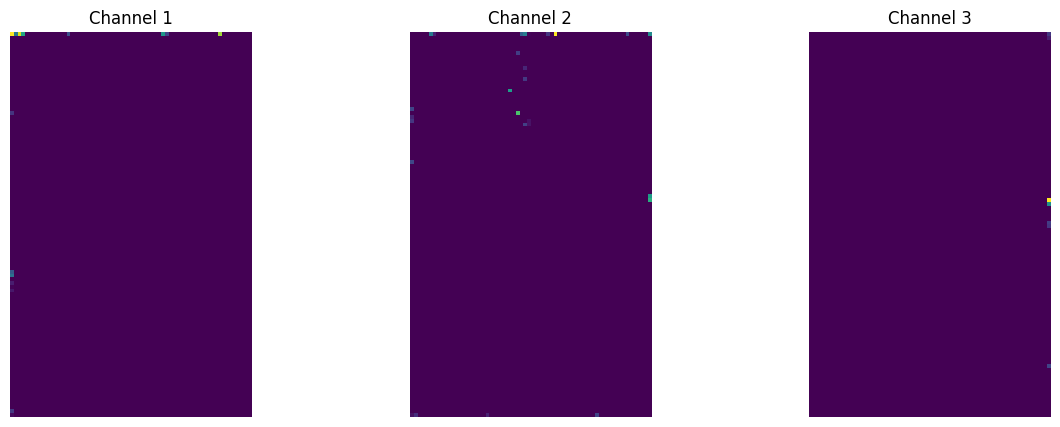

In [ ]:
for i in range(len(layers)-1):
  show_layer_outputs(random_img, i)

## Decoder

In [ ]:
def match_and_concatenate(upsampled, bypass):
    """Ajusta el tamaño del tensor upsampled para que coincida exactamente con bypass antes de concatenar."""
    b_shape = bypass.shape
    u_shape = upsampled.shape

    # Calcular diferencias de dimensiones en altura y anchura
    height_diff = b_shape[1] - u_shape[1]
    width_diff = b_shape[2] - u_shape[2]

    # Aplicar ZeroPadding2D si las dimensiones del tensor upsampled son más pequeñas
    if height_diff > 0 or width_diff > 0:
        top_pad = height_diff // 2
        bottom_pad = height_diff - top_pad
        left_pad = width_diff // 2
        right_pad = width_diff - left_pad
        upsampled = tf.keras.layers.ZeroPadding2D(
            padding=((top_pad, bottom_pad), (left_pad, right_pad))
        )(upsampled)

    return tf.keras.layers.concatenate([upsampled, bypass])

# --- DECODER UNET ---
# Partimos del bloque más profundo (block4: 128 filtros)

# Bloque de Expansión 1 (Conecta con block3)
x = tf.keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(block4)
x = match_and_concatenate(x, block3)
x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)

# Bloque de Expansión 2 (Conecta con block2)
x = tf.keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(x)
x = match_and_concatenate(x, block2)
x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)

# Bloque de Expansión 3 (Conecta con block1)
x = tf.keras.layers.Conv2DTranspose(16, 2, strides=2, padding="same")(x)
x = match_and_concatenate(x, block1)
x = tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu")(x)

# Capa de Clasificación Final (4 clases para segmentación)
outputs = tf.keras.layers.Conv2D(4, kernel_size=1, padding="same", activation="softmax")(x)

# Construcción final de la UNet
unet_model = keras.Model(inputs=inputs, outputs=outputs)
unet_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 820, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 820, 512,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 820, 512,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 410, 256,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 410, 256,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 410, 256,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 205, 128,  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 205, 128,  │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 205, 128,  │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 102, 64,   │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 102, 64,   │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 102, 64,   │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 204, 128,  │     32,832 │ conv2d_7[0][0]    │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 205, 128,  │          0 │ conv2d_transpose… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 205, 128,  │          0 │ zero_padding2d[0… │
│ (Concatenate)       │ 128)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 205, 128,  │     73,792 │ concatenate_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 205, 128,  │     36,928 │ conv2d_8[0][0]  

 Total params: 482,084 (1.84 MB)

 Trainable params: 482,084 (1.84 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [ ]:
def load_and_preprocess_image(img_path, mask_path):
    # Cargar y decodificar la imagen
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, (820, 512)) # Redimensionar al formato (alto, ancho) esperado

    # Cargar y decodificar la máscara
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, (820, 512), method="nearest")
    mask = tf.cast(mask, tf.int32)

    return img, mask

# Preparar las listas de rutas completas para el set de entrenamiento
train_img_paths = [os.path.join(TRAIN_IMG_DIR, f) for f in train_files]
train_mask_paths = [os.path.join(TRAIN_MASK_DIR, f.replace(".jpg", ".png")) for f in train_files]

# Crear el Dataset de TensorFlow
BATCH_SIZE = 4
train_dataset = tf.data.Dataset.from_tensor_slices((train_img_paths, train_mask_paths))
train_dataset = train_dataset.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.shuffle(buffer_size=100).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

print("Dataset de entrenamiento creado correctamente.")

Dataset de entrenamiento creado correctamente.


In [ ]:
# Compilación del modelo
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo compilado exitosamente. Iniciando entrenamiento de prueba...")

# Entrenamiento del modelo (ejecutamos 3 épocas iniciales para corroborar el flujo correcto)
history = unet_model.fit(
    train_dataset,
    epochs=3
)

Modelo compilado exitosamente. Iniciando entrenamiento de prueba...
Epoch 1/3
66/66 ━━━━━━━━━━━━━━━━━━━━ 1015s 15s/step - accuracy: 0.8155 - loss: 0.3038
Epoch 2/3
66/66 ━━━━━━━━━━━━━━━━━━━━ 982s 15s/step - accuracy: 0.8226 - loss: 0.2790
Epoch 3/3
66/66 ━━━━━━━━━━━━━━━━━━━━ 1053s 15s/step - accuracy: 0.8852 - loss: 0.2559


### Predicciones y Visualización de Resultados

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 825ms/step


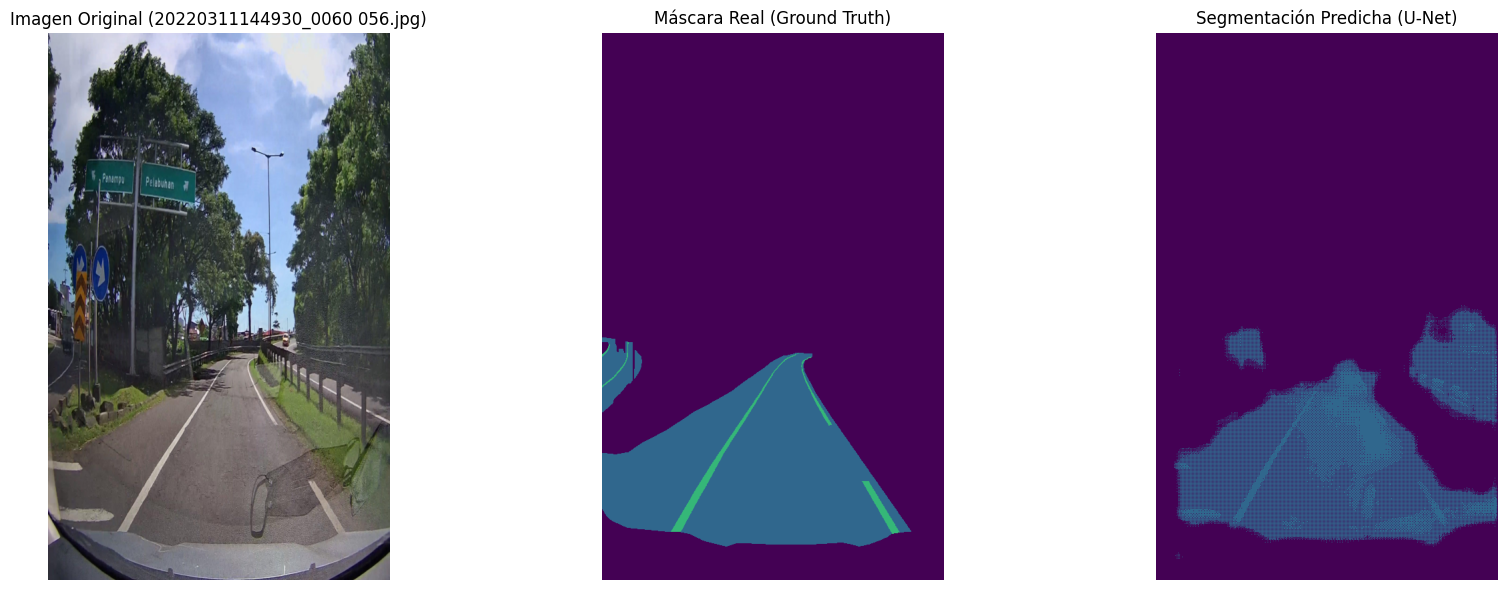

In [ ]:
def predict_and_plot(model, img_dir, mask_dir, files_list):
    # 1. Seleccionar una imagen aleatoria de la lista
    random_file = random.choice(files_list)
    img_path = os.path.join(img_dir, random_file)
    mask_path = os.path.join(mask_dir, random_file.replace(".jpg", ".png"))

    # 2. Cargar y preparar la imagen para el modelo
    img_raw = Image.open(img_path).convert("RGB")
    img_resized = img_raw.resize((512, 820), Image.Resampling.BILINEAR) # ancho, alto
    img_tensor = np.array(img_resized) / 255.0
    img_tensor = np.expand_dims(img_tensor, axis=0) # Añadir dimensión de batch

    # 3. Cargar la máscara real correspondiente
    mask_raw = Image.open(mask_path)
    mask_resized = mask_raw.resize((512, 820), Image.Resampling.NEAREST)
    mask_array = np.array(mask_resized)

    # 4. Realizar la predicción con el modelo
    pred = model.predict(img_tensor)
    pred_mask = np.argmax(pred[0], axis=-1) # Tomar el canal con mayor probabilidad

    # 5. Visualizar los resultados comparativamente
    plt.figure(figsize=(18, 6))

    # Imagen Original
    plt.subplot(1, 3, 1)
    plt.imshow(img_resized)
    plt.title(f"Imagen Original ({random_file})")
    plt.axis("off")

    # Máscara Real
    plt.subplot(1, 3, 2)
    plt.imshow(mask_array, cmap="viridis", vmin=0, vmax=3)
    plt.title("Máscara Real (Ground Truth)")
    plt.axis("off")

    # Máscara Predicha por la Red
    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask, cmap="viridis", vmin=0, vmax=3)
    plt.title("Segmentación Predicha (U-Net)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Ejecutar la predicción con una imagen del dataset de entrenamiento
predict_and_plot(unet_model, TRAIN_IMG_DIR, TRAIN_MASK_DIR, train_files)

# Resumen

## Resumen de la Fase de Modelado 1

Este archivo se encarga de implementar y validar el flujo inicial de diseño de arquitectura, carga de datos optimizada y entrenamiento de prueba para un modelo de segmentación semántica (U-Net) en TensorFlow/Keras:

### 1. Preparación y Análisis de Resoluciones
- Conexión con los datos estructurados en Google Drive obtenidos de la fase ETL previa.
- Evaluación visual y de dimensionalidad de imágenes y máscaras en múltiples resoluciones (`640x1024`, `512x819`, `256x410`, `128x205`) seleccionando la configuración de `512x820` como balance óptimo entre costo computacional y preservación de detalles finos (como las líneas de carril).
- Fijación de una semilla aleatoria (`SEED = 67`) para garantizar la total reproducibilidad en la inicialización de pesos y división de datos.

### 2. Diseño de Arquitectura (U-Net)
- **Encoder (Extractor de Características):** Construcción de un codificador basado en bloques de convolución y MaxPool, guardando las salidas intermedias (`block1` a `block4`) para actuar como conexiones de salto (*skip connections*).
- **Decoder (Reconstrucción Espacial):** Implementación de bloques de expansión mediante `Conv2DTranspose` concatenando las características del codificador con una función personalizada de alineación espacial (`match_and_concatenate`) mediante `ZeroPadding2D` para mitigar discrepancias dimensionales.
- **Clasificación Píxel a Píxel:** Capa final de convolución `1x1` con activación Softmax para clasificar cada píxel en una de las 4 categorías del dataset.

### 3. Pipeline de Datos con `tf.data`
- Creación de un pipeline de carga asíncrono y eficiente utilizando la API `tf.data.Dataset`.
- Preprocesamiento automatizado que incluye normalización de imágenes a escala `[0, 1]` y redimensionamiento dinámico a la resolución del modelo utilizando interpolación Bilineal para imágenes y del vecino más cercano (*Nearest Neighbor*) para las máscaras de etiquetas.
- Optimización del rendimiento mediante el uso de `prefetch` y `AUTOTUNE` para acelerar el flujo de alimentación a la GPU/CPU.

### 4. Compilación y Entrenamiento de Prueba (Overfitting Control)
- Compilación del modelo utilizando el optimizador **Adam** con una tasa de aprendizaje de `1e-4` y la función de pérdida **Sparse Categorical Crossentropy**.
- Entrenamiento de validación rápida durante 3 épocas iniciales para corroborar el correcto flujo de gradientes, logrando una reducción consistente en la pérdida y un incremento rápido en la métrica de *accuracy*.

### 5. Predicción y Visualización Comparativa
- Implementación de un flujo de inferencia para generar segmentaciones en imágenes de prueba aleatorias.
- Generación de gráficas comparativas triples que muestran lado a lado: la Imagen Original, la Máscara Real (Ground Truth) y la Máscara Predicha por la Red, facilitando la evaluación cualitativa visual del rendimiento del modelo.

---

## Estado actual del cuaderno

- [x] Configuración del entorno y verificación de GPU.
- [x] Análisis visual de escalado y resoluciones óptimas.
- [x] Construcción del Encoder con guardado de activaciones intermedias.
- [x] Definición del Decoder U-Net con capas de concatenación alineadas.
- [x] Creación del pipeline eficiente de entrenamiento con `tf.data`.
- [x] Compilación y ejecución exitosa del ciclo de entrenamiento inicial (3 épocas).
- [x] Visualización comparativa cualitativa de predicciones vs. Ground Truth.